# Weeks 3–4: Predicting land surface temperature

**Goal:** test whether the vegetation signal (NDVI) improves predictions of land surface temperature (LST).

We compare two approaches:

- **Baseline:** uses month and location to represent season and geography.
- **NDVI:** uses the same information **plus** the vegetation index for that month.

We also compare a simple OLS model with XGBoost, a more flexible model. All models predict LST, so lower error means better performance. We use 2013–2021 to train, 2022 to choose the OLS spatial form, and 2023–2024 for the final test.

> **How to read this notebook:** run the cells in order. The short notes explain what each step does and why it is needed.

## 1. Set up the data and separate the time periods

**Why separate the years?** A model should be tested on data it has not seen during training. Otherwise, a good result might simply mean the model memorized the training period.

- **2013–2021 — fit:** the model learns patterns from these rows.
- **2022 — validation:** used only to decide whether the OLS spatial effect should be linear or curved.
- **2023–2024 — final test:** provides an untouched check of model performance.

We also use only **development locations** here. This keeps the separate spatial-test locations reserved.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
DATA = ROOT / "outputs/evergreen_reference_sample_recreated.parquet"
OUT = ROOT / "reports/model_comparison"
OUT.mkdir(parents=True, exist_ok=True)
COLS = ["pixel_id","year","month","ndvi","lst","lon","lat","easting_m","northing_m","geographic_split","calendar_role"]
df = pd.read_parquet(DATA, columns=COLS)

def valid(role):
    return df[(df.geographic_split == "development") & (df.calendar_role == role) & df.lst.notna() & df.ndvi.notna()].copy()

train = valid("fit")
validation = valid("validation")
test = valid("final_evaluation")
loc = train[["pixel_id","easting_m","northing_m"]].drop_duplicates("pixel_id")
center_e = loc.easting_m.mean()/1000
center_n = loc.northing_m.mean()/1000
for frame in (df, train, validation, test):
    frame["x_km"] = frame.easting_m/1000 - center_e
    frame["y_km"] = frame.northing_m/1000 - center_n
print({"training_rows": len(train), "validation_rows": len(validation), "test_rows": len(test), "test_pixels": test.pixel_id.nunique()})

{'training_rows': 29838595, 'validation_rows': 3203185, 'test_rows': 6718917, 'test_pixels': 300582}


## 2. Choose the inputs for the OLS models

**Month** is included because temperature follows seasonal patterns. **Location** is included because nearby or broad geographic areas can differ in temperature.

The baseline model uses month and location. The NDVI model adds NDVI, a measure of vegetation condition.

We test two forms of location: **linear** and **quadratic** (allowing more curved spatial patterns).

In [2]:
BASE = ["intercept"] + [f"month_{m}" for m in range(2,13)] + ["x_km","y_km"]
QUAD = BASE + ["x_km_sq","x_y","y_km_sq"]
def design(frame, spatial="linear", use_ndvi=False):
    x, y = frame.x_km.to_numpy(float), frame.y_km.to_numpy(float)
    columns = [np.ones(len(frame))] + [(frame.month.to_numpy() == m).astype(float) for m in range(2,13)] + [x,y]
    if spatial == "quadratic": columns += [x*x, x*y, y*y]
    if use_ndvi: columns += [frame.ndvi.to_numpy(float)]
    return np.column_stack(columns)
def fit_ols(frame, spatial, use_ndvi):
    return np.linalg.lstsq(design(frame, spatial, use_ndvi), frame.lst.to_numpy(float), rcond=None)[0]
def score(actual, prediction):
    y = actual.to_numpy(float) if hasattr(actual, "to_numpy") else np.asarray(actual, float)
    e = y - prediction; nz = y != 0; den = ((y-y.mean())**2).sum()
    return {"mae": np.abs(e).mean(), "median_absolute_error": np.median(np.abs(e),), "rmse": np.sqrt((e**2).mean()), "mape_percent": np.mean(np.abs(e[nz]/y[nz]))*100, "r2": np.nan if den == 0 else 1-(e**2).sum()/den, "mean_signed_error": e.mean()}

## 3. Decide how location should be represented

**Why use 2022?** It gives us a fair choice before 2023–2024 are used for the final test.

Lower MAE or RMSE means better predictions. We compare both spatial forms and also check whether adding NDVI helps in each case.

In [3]:
candidates = {}
for spatial in ("linear", "quadratic"):
    for use_ndvi in (False, True):
        beta = fit_ols(train, spatial, use_ndvi)
        pred = design(validation, spatial, use_ndvi) @ beta
        candidates[f"{spatial}_{'ndvi' if use_ndvi else 'baseline'}"] = {"beta": beta.tolist(), **score(validation.lst, pred)}
chosen_spatial = min(("linear", "quadratic"), key=lambda s: candidates[f"{s}_baseline"]["rmse"])
pd.DataFrame(candidates).T[["mae","median_absolute_error","rmse","mape_percent","r2"]]

,mae,median_absolute_error,rmse,mape_percent,r2
linear_baseline,3.525103,3.08579,4.323149,8.822102,0.723523
linear_ndvi,3.496351,3.052923,4.299546,8.760659,0.726533
quadratic_baseline,3.426172,3.066798,4.169523,8.544587,0.742823
quadratic_ndvi,3.414775,3.048426,4.159338,8.524638,0.744078


## 4. Fit the final OLS models

Each model is now fitted on the 2013–2021 data only. The chosen spatial form is shared by both models, so the only feature difference is whether NDVI is included. This makes the comparison easier to interpret.

In [4]:
ols = {}
for name, use_ndvi in [("baseline", False), ("ndvi", True)]:
    beta = fit_ols(train, chosen_spatial, use_ndvi)
    ols[name] = {"beta": beta, "use_ndvi": use_ndvi}
    print(name, "features:", (BASE if chosen_spatial == "linear" else QUAD) + (["ndvi"] if use_ndvi else []))

baseline features: ['intercept', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12', 'x_km', 'y_km', 'x_km_sq', 'x_y', 'y_km_sq']


ndvi features: ['intercept', 'month_2', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_9', 'month_10', 'month_11', 'month_12', 'x_km', 'y_km', 'x_km_sq', 'x_y', 'y_km_sq', 'ndvi']


## 5. Test the OLS models on 2023–2024

**Why report several metrics?** Each metric describes error in a slightly different way:

- **MAE:** typical absolute error, in °C.
- **Median absolute error:** typical error without excessive influence from extreme misses.
- **RMSE:** penalizes larger misses more heavily.
- **MAPE:** relative percentage error.
- **R²:** how much variation in observed LST the predictions explain.

A small positive/negative signed error means the model is, on average, close to the true value; it does not prove accuracy for every location.

In [5]:
pred = test[["pixel_id","year","month","lst","ndvi"]].copy()
for name, spec in ols.items(): pred[f"pred_{name}"] = design(test, chosen_spatial, spec["use_ndvi"]) @ spec["beta"]
pred["err_baseline"] = pred.lst - pred.pred_baseline
pred["err_ndvi"] = pred.lst - pred.pred_ndvi
rows=[]
for period, part in [("2023_2024", pred), ("2023", pred[pred.year==2023]), ("2024", pred[pred.year==2024])]:
    for name in ("baseline", "ndvi"):
        rows.append({"model":name, "period":period, **score(part.lst, part[f"pred_{name}"].to_numpy()), "pixels":part.pixel_id.nunique(), "observations":len(part)})
ols_metrics = pd.DataFrame(rows)
ols_metrics.to_csv(OUT/"later_year_metrics.csv", index=False)
ols_metrics[ols_metrics.period=="2023_2024"]

,model,period,mae,median_absolute_error,rmse,mape_percent,r2,mean_signed_error,pixels,observations
0,baseline,2023_2024,3.445319,3.068330,4.199254,8.759224,0.762355,0.095291,300582,6718917
1,ndvi,2023_2024,3.428879,3.053714,4.181651,8.717258,0.764343,0.123967,300582,6718917


## 6. Measure whether NDVI improves OLS predictions

This table compares the two OLS models on the **same rows**. A positive MAE, median-error, or RMSE gain means the NDVI model made smaller errors. A positive R² gain means it explained slightly more variation.

In [6]:
gains=[]
for period in ols_metrics.period.unique():
    q=ols_metrics[ols_metrics.period==period].set_index("model")
    gains.append({"period":period, "delta_mae":q.loc["baseline","mae"]-q.loc["ndvi","mae"], "delta_median_absolute_error":q.loc["baseline","median_absolute_error"]-q.loc["ndvi","median_absolute_error"], "delta_rmse":q.loc["baseline","rmse"]-q.loc["ndvi","rmse"], "delta_mape_percent":q.loc["baseline","mape_percent"]-q.loc["ndvi","mape_percent"], "delta_r2":q.loc["ndvi","r2"]-q.loc["baseline","r2"]})
pd.DataFrame(gains).to_csv(OUT/"paired_gains.csv", index=False)
pd.DataFrame(gains)

,period,delta_mae,delta_median_absolute_error,delta_rmse,delta_mape_percent,delta_r2
0,2023_2024,0.016440,0.014616,0.017603,0.041966,0.001988
1,2023,0.014822,0.015418,0.014609,0.036214,0.001785
2,2024,0.017961,0.014317,0.020434,0.047375,0.002158


## 7. Compare OLS with XGBoost

**Why add XGBoost?** OLS assumes a mostly fixed relationship between inputs and temperature. XGBoost can learn more flexible nonlinear patterns and interactions.

Both XGBoost models use the same 2-million-row training sample, the same random seed, month and location features, and the same fair test periods. The only difference is that the NDVI model also receives NDVI.

In [7]:
from xgboost import XGBRegressor
def xgb_features(frame, use_ndvi):
    a=np.column_stack([frame.month.to_numpy(float), frame.x_km.to_numpy(float), frame.y_km.to_numpy(float)])
    return np.column_stack([a, frame.ndvi.to_numpy(float)]) if use_ndvi else a
sample=train.sample(n=min(2_000_000,len(train)), random_state=42)
params=dict(n_estimators=300,max_depth=8,learning_rate=.08,subsample=.8,colsample_bytree=.9,tree_method="hist",objective="reg:squarederror",n_jobs=4,random_state=42)
xgb_rows=[]; xgb_pred=test[["pixel_id","year","month","ndvi","lst"]].copy()
for name,use_ndvi in [("baseline",False),("ndvi",True)]:
    model=XGBRegressor(**params)
    model.fit(xgb_features(sample,use_ndvi), sample.lst.to_numpy(float), eval_set=[(xgb_features(validation,use_ndvi),validation.lst.to_numpy(float))], verbose=False)
    xgb_pred[f"pred_{name}"]=model.predict(xgb_features(test,use_ndvi))
    xgb_rows.append({"model":"xgboost_"+name,"period":"2022_validation",**score(validation.lst,model.predict(xgb_features(validation,use_ndvi))),"pixels":validation.pixel_id.nunique(),"observations":len(validation)})
for period,part in [("2023_2024",xgb_pred),("2023",xgb_pred[xgb_pred.year==2023]),("2024",xgb_pred[xgb_pred.year==2024])]:
    for name in ("baseline","ndvi"): xgb_rows.append({"model":"xgboost_"+name,"period":period,**score(part.lst,part[f"pred_{name}"].to_numpy()),"pixels":part.pixel_id.nunique(),"observations":len(part)})
xgb_metrics=pd.DataFrame(xgb_rows); xgb_metrics.to_csv(OUT/"xgboost_metrics.csv",index=False); xgb_pred["err_baseline"]=xgb_pred.lst-xgb_pred.pred_baseline; xgb_pred["err_ndvi"]=xgb_pred.lst-xgb_pred.pred_ndvi; xgb_pred.to_parquet(OUT/"xgboost_predictions.parquet",index=False)
xgb_metrics[xgb_metrics.period=="2023_2024"]

,model,period,mae,median_absolute_error,rmse,mape_percent,r2,mean_signed_error,pixels,observations
2,xgboost_baseline,2023_2024,1.897257,1.574833,2.415649,4.843101,0.921359,0.086377,300582,6718917
3,xgboost_ndvi,2023_2024,1.815698,1.491783,2.320363,4.609670,0.927440,0.159514,300582,6718917


## 8. OLS Visual diagnostics

These plots show **where** the model succeeds and **where** it struggles. Saving each figure beside the CSV and parquet outputs lets the results be reused in a report or presentation.

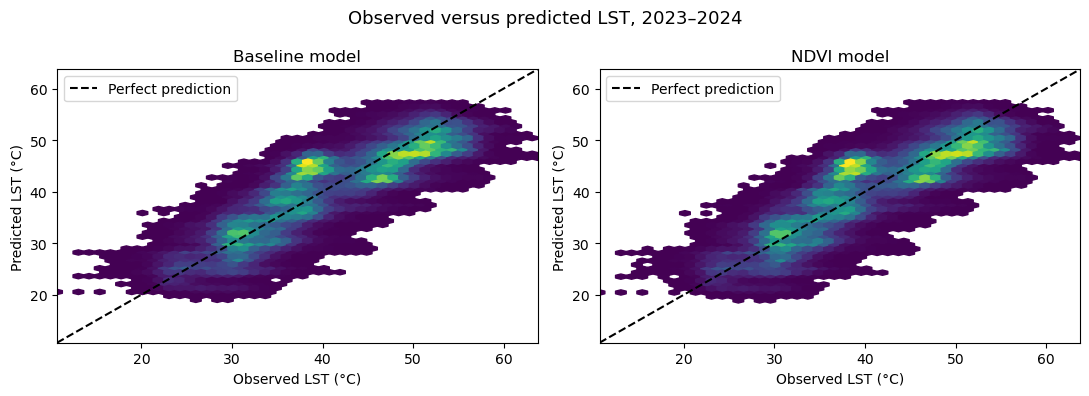

Interpretation: points close to the dashed line are accurate. A broad cloud of points means the model misses more variation.


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
low, high = pred.lst.min(), pred.lst.max()

for axis, name in zip(ax, ("baseline", "ndvi")):
    points = axis.hexbin(pred.lst, pred[f"pred_{name}"], gridsize=45, mincnt=1, cmap="viridis")
    axis.plot([low, high], [low, high], "k--", linewidth=1.5, label="Perfect prediction")
    axis.set(
        xlim=(low, high), ylim=(low, high),
        xlabel="Observed LST (°C)", ylabel="Predicted LST (°C)",
        title=f"{'Baseline' if name == 'baseline' else 'NDVI'} model"
    )
    axis.legend(loc="upper left")

fig.suptitle("Observed versus predicted LST, 2023–2024", fontsize=13)
fig.tight_layout()
fig.savefig(OUT / "observed_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

print("Interpretation: points close to the dashed line are accurate. A broad cloud of points means the model misses more variation.")

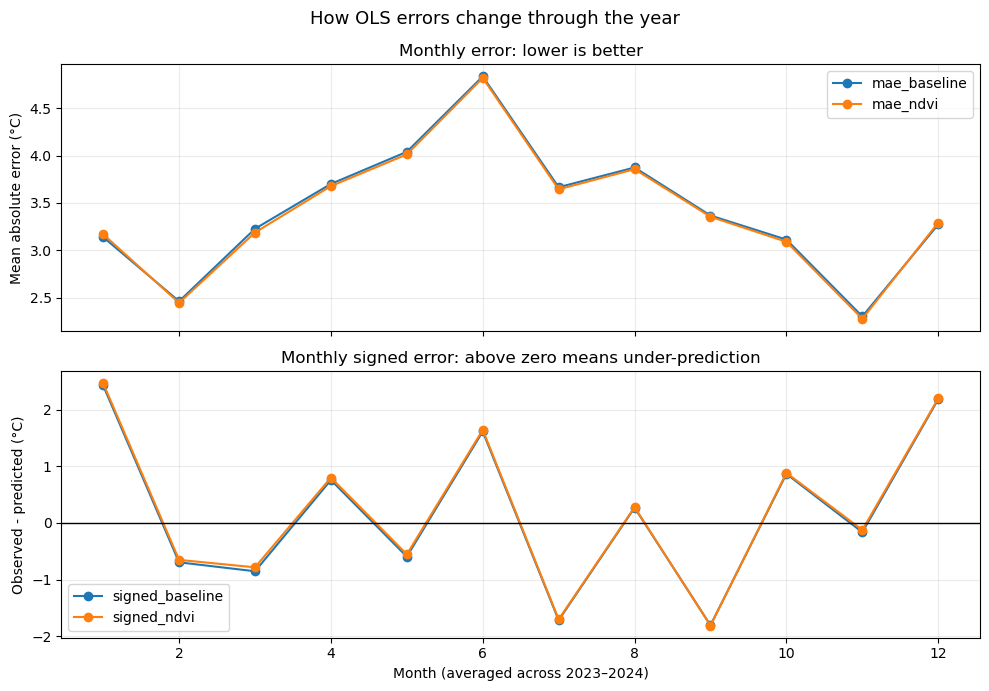

Interpretation: the top panel compares typical error by month. In the bottom panel, positive values mean predictions were too low; negative values mean they were too high.


In [9]:
monthly = pred.assign(
    abs_baseline=pred.err_baseline.abs(),
    abs_ndvi=pred.err_ndvi.abs()
).groupby("month").agg(
    mae_baseline=("abs_baseline", "mean"),
    mae_ndvi=("abs_ndvi", "mean"),
    signed_baseline=("err_baseline", "mean"),
    signed_ndvi=("err_ndvi", "mean"),
    observations=("lst", "size")
).reset_index()
monthly.to_csv(OUT / "monthly_errors.csv", index=False)

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
monthly.plot(x="month", y=["mae_baseline", "mae_ndvi"], ax=ax[0], marker="o")
ax[0].set_title("Monthly error: lower is better")
ax[0].set_ylabel("Mean absolute error (°C)")
ax[0].grid(alpha=.25)

monthly.plot(x="month", y=["signed_baseline", "signed_ndvi"], ax=ax[1], marker="o")
ax[1].axhline(0, color="black", linewidth=1)
ax[1].set_title("Monthly signed error: above zero means under-prediction")
ax[1].set_xlabel("Month (averaged across 2023–2024)")
ax[1].set_ylabel("Observed - predicted (°C)")
ax[1].grid(alpha=.25)

fig.suptitle("How OLS errors change through the year", fontsize=13)
fig.tight_layout()
fig.savefig(OUT / "errors_over_time.png", dpi=160, bbox_inches="tight")
plt.show()

print("Interpretation: the top panel compares typical error by month. In the bottom panel, positive values mean predictions were too low; negative values mean they were too high.")

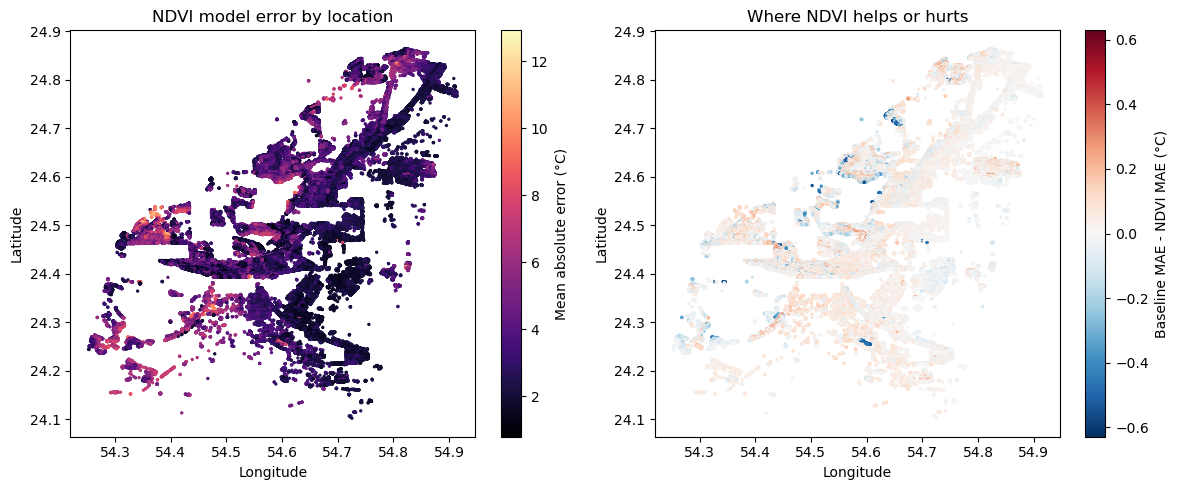

Interpretation: red in the right map means NDVI reduced error there; blue means the baseline was better.


In [10]:
locerr = pred.groupby("pixel_id").agg(
    mae_baseline=("err_baseline", lambda values: np.abs(values).mean()),
    mae_ndvi=("err_ndvi", lambda values: np.abs(values).mean())
).reset_index()
locerr["gain"] = locerr.mae_baseline - locerr.mae_ndvi
locerr = locerr.merge(
    df[["pixel_id", "lon", "lat"]].drop_duplicates("pixel_id"),
    on="pixel_id"
)
locerr.to_csv(OUT / "location_errors.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
map1 = ax[0].scatter(locerr.lon, locerr.lat, c=locerr.mae_ndvi, s=2, cmap="magma")
ax[0].set_title("NDVI model error by location")
ax[0].set_xlabel("Longitude")
ax[0].set_ylabel("Latitude")
fig.colorbar(map1, ax=ax[0], label="Mean absolute error (°C)")

limit = np.nanmax(np.abs(locerr.gain))
map2 = ax[1].scatter(locerr.lon, locerr.lat, c=locerr.gain, s=2, cmap="RdBu_r", vmin=-limit, vmax=limit)
ax[1].set_title("Where NDVI helps or hurts")
ax[1].set_xlabel("Longitude")
ax[1].set_ylabel("Latitude")
fig.colorbar(map2, ax=ax[1], label="Baseline MAE - NDVI MAE (°C)")

fig.tight_layout()
fig.savefig(OUT / "location_error_maps.png", dpi=160, bbox_inches="tight")
plt.show()

print("Interpretation: red in the right map means NDVI reduced error there; blue means the baseline was better.")

## 9. XGBoost visual diagnostics

These plots use the same test observations and visualizations as the OLS diagnostics above. That makes it easier to see whether XGBoost's lower overall error also means better predictions across temperatures, months, and locations.

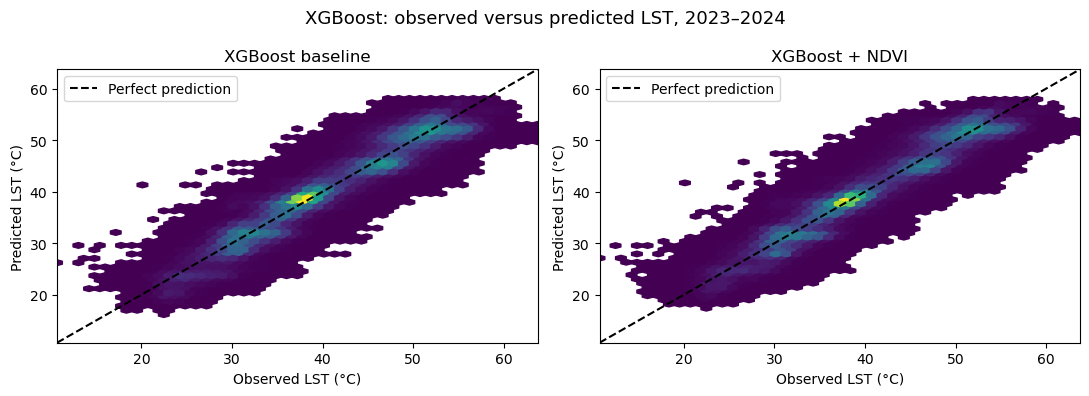

Interpretation: points closer to the dashed line are more accurate. Compare the spread with the OLS figure using the same axes.


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
low, high = pred.lst.min(), pred.lst.max()

for axis, name in zip(ax, ("baseline", "ndvi")):
    axis.hexbin(xgb_pred.lst, xgb_pred[f"pred_{name}"], gridsize=45, mincnt=1, cmap="viridis")
    axis.plot([low, high], [low, high], "k--", linewidth=1.5, label="Perfect prediction")
    axis.set(
        xlim=(low, high), ylim=(low, high),
        xlabel="Observed LST (°C)", ylabel="Predicted LST (°C)",
        title=f"XGBoost {'baseline' if name == 'baseline' else '+ NDVI'}"
    )
    axis.legend(loc="upper left")

fig.suptitle("XGBoost: observed versus predicted LST, 2023–2024", fontsize=13)
fig.tight_layout()
fig.savefig(OUT / "xgboost_observed_vs_predicted.png", dpi=160, bbox_inches="tight")
plt.show()

print("Interpretation: points closer to the dashed line are more accurate. Compare the spread with the OLS figure using the same axes.")

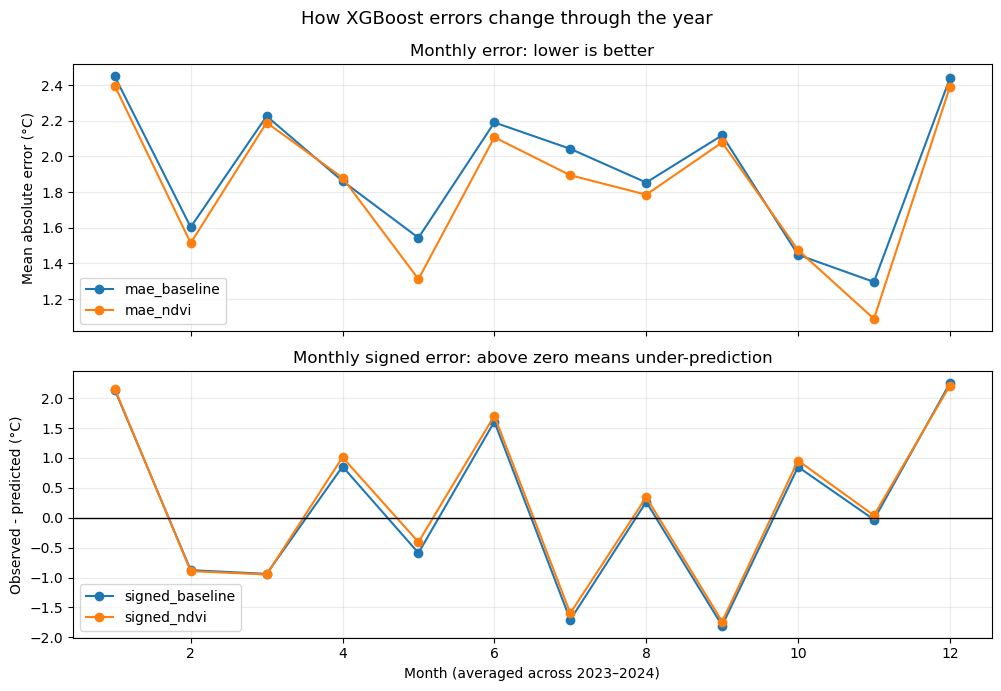

Interpretation: the top panel shows the month-to-month error size. In the bottom panel, positive values mean predictions were too low; negative values mean they were too high.


In [12]:
xgb_monthly = xgb_pred.assign(
    abs_baseline=xgb_pred.err_baseline.abs(),
    abs_ndvi=xgb_pred.err_ndvi.abs()
).groupby("month").agg(
    mae_baseline=("abs_baseline", "mean"),
    mae_ndvi=("abs_ndvi", "mean"),
    signed_baseline=("err_baseline", "mean"),
    signed_ndvi=("err_ndvi", "mean"),
    observations=("lst", "size")
).reset_index()
xgb_monthly.to_csv(OUT / "xgboost_monthly_errors.csv", index=False)

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
xgb_monthly.plot(x="month", y=["mae_baseline", "mae_ndvi"], ax=ax[0], marker="o")
ax[0].set_title("Monthly error: lower is better")
ax[0].set_ylabel("Mean absolute error (°C)")
ax[0].grid(alpha=.25)

xgb_monthly.plot(x="month", y=["signed_baseline", "signed_ndvi"], ax=ax[1], marker="o")
ax[1].axhline(0, color="black", linewidth=1)
ax[1].set_title("Monthly signed error: above zero means under-prediction")
ax[1].set_xlabel("Month (averaged across 2023–2024)")
ax[1].set_ylabel("Observed - predicted (°C)")
ax[1].grid(alpha=.25)

fig.suptitle("How XGBoost errors change through the year", fontsize=13)
fig.tight_layout()
fig.savefig(OUT / "xgboost_errors_over_time.png", dpi=160, bbox_inches="tight")
plt.show()

print("Interpretation: the top panel shows the month-to-month error size. In the bottom panel, positive values mean predictions were too low; negative values mean they were too high.")

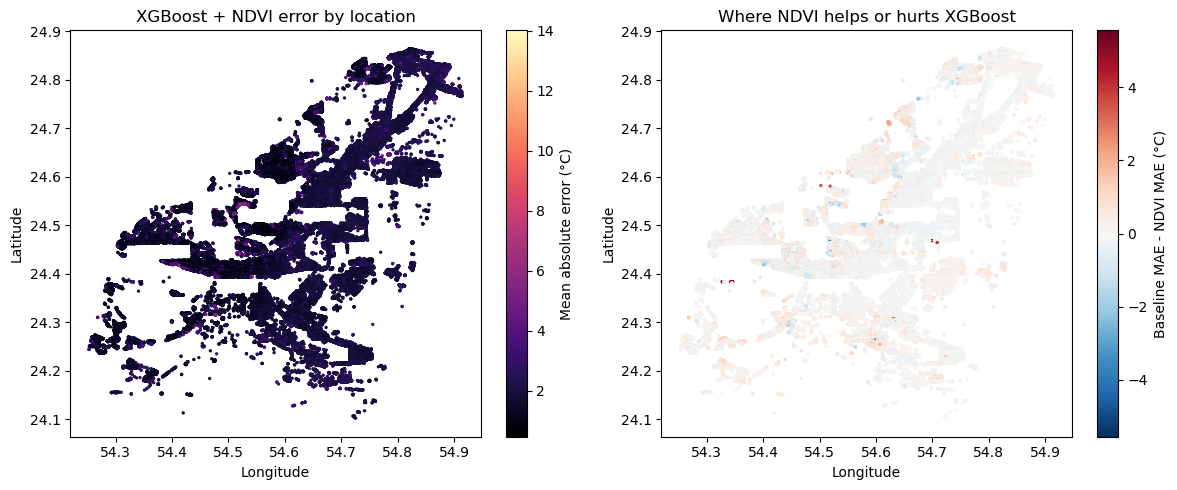

Interpretation: red means the NDVI version reduced error at that location; blue means the baseline was better. Pale areas mean the models were similar.


In [13]:
xgb_locerr = xgb_pred.groupby("pixel_id").agg(
    mae_baseline=("err_baseline", lambda values: np.abs(values).mean()),
    mae_ndvi=("err_ndvi", lambda values: np.abs(values).mean())
).reset_index()
xgb_locerr["gain"] = xgb_locerr.mae_baseline - xgb_locerr.mae_ndvi
xgb_locerr = xgb_locerr.merge(
    df[["pixel_id", "lon", "lat"]].drop_duplicates("pixel_id"),
    on="pixel_id"
)
xgb_locerr.to_csv(OUT / "xgboost_location_errors.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
map1 = ax[0].scatter(xgb_locerr.lon, xgb_locerr.lat, c=xgb_locerr.mae_ndvi, s=2, cmap="magma")
ax[0].set_title("XGBoost + NDVI error by location")
ax[0].set_xlabel("Longitude")
ax[0].set_ylabel("Latitude")
fig.colorbar(map1, ax=ax[0], label="Mean absolute error (°C)")

limit = np.nanmax(np.abs(xgb_locerr.gain))
map2 = ax[1].scatter(xgb_locerr.lon, xgb_locerr.lat, c=xgb_locerr.gain, s=2, cmap="RdBu_r", vmin=-limit, vmax=limit)
ax[1].set_title("Where NDVI helps or hurts XGBoost")
ax[1].set_xlabel("Longitude")
ax[1].set_ylabel("Latitude")
fig.colorbar(map2, ax=ax[1], label="Baseline MAE - NDVI MAE (°C)")

fig.tight_layout()
fig.savefig(OUT / "xgboost_location_error_maps.png", dpi=160, bbox_inches="tight")
plt.show()

print("Interpretation: red means the NDVI version reduced error at that location; blue means the baseline was better. Pale areas mean the models were similar.")

## Plain-English conclusion

**What did we test?** We asked whether adding NDVI improves prediction beyond month and location.

**Overall answer:** yes, but the improvement is small. On 2023–2024, the OLS NDVI model reduced MAE from **3.445 °C to 3.429 °C** and RMSE from **4.199 °C to 4.182 °C**. XGBoost performed substantially better than OLS: its NDVI model reached **1.816 °C MAE** and **2.320 °C RMSE**.

**What does this mean?** In these development locations, vegetation index information is useful, and flexible nonlinear patterns are even more important. XGBoost is the stronger predictive model in this test.

**What should we avoid claiming?** NDVI is associated with prediction improvement; it does not prove that vegetation caused temperature differences. The 2023–2024 result also describes the held-out years and development locations, not every location or future condition.

**Best next step:** if this workflow becomes a reporting or forecasting system, test the reserved spatial locations and add an approved exclusion buffer before making geographic claims.

## 10. Overall model comparison

This final chart puts every approach on the same scale. It answers the practical question: “How much error remains after considering month, location, NDVI, and model flexibility?”

,model,mae,rmse
0,OLS baseline,3.445319,4.199254
1,OLS + NDVI,3.428879,4.181651
2,XGBoost baseline,1.897257,2.415649
3,XGBoost + NDVI,1.815698,2.320363


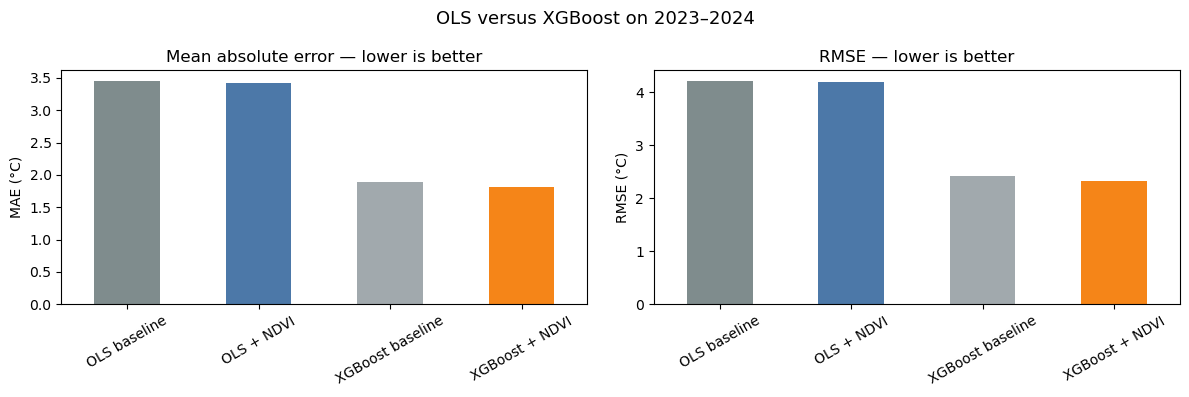

Interpretation: XGBoost has roughly half the error of OLS. Within each model family, NDVI produces a smaller additional improvement.


In [14]:
comparison = pd.DataFrame([
    {"model": "OLS baseline", "mae": 3.445318510617289, "rmse": 4.1992541004484085},
    {"model": "OLS + NDVI", "mae": 3.4288786820024315, "rmse": 4.181651401709993},
    {"model": "XGBoost baseline", "mae": 1.8972574668756794, "rmse": 2.4156489303123786},
    {"model": "XGBoost + NDVI", "mae": 1.8156975766448753, "rmse": 2.320362560069435},
])
display(comparison)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
comparison.plot.bar(x="model", y="mae", ax=ax[0], legend=False, color=["#7f8c8d", "#4c78a8", "#a1a9ad", "#f58518"])
ax[0].set_title("Mean absolute error — lower is better")
ax[0].set_ylabel("MAE (°C)")
ax[0].set_xlabel("")
ax[0].tick_params(axis="x", rotation=30)

comparison.plot.bar(x="model", y="rmse", ax=ax[1], legend=False, color=["#7f8c8d", "#4c78a8", "#a1a9ad", "#f58518"])
ax[1].set_title("RMSE — lower is better")
ax[1].set_ylabel("RMSE (°C)")
ax[1].set_xlabel("")
ax[1].tick_params(axis="x", rotation=30)

fig.suptitle("OLS versus XGBoost on 2023–2024", fontsize=13)
fig.tight_layout()
fig.savefig(OUT / "model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

print("Interpretation: XGBoost has roughly half the error of OLS. Within each model family, NDVI produces a smaller additional improvement.")